# Tarea 05: Cálculo simbólico

**Semana 5** · Entrega: antes de la clase de la Semana 6

## Objetivos de la tarea

1. Derivar una expresión simbólica y usar la derivada para localizar un
   equilibrio con `solve`.
2. Resolver una ecuación diferencial con `dsolve` imponiendo condiciones
   iniciales.
3. Extraer el caso límite de una solución con `limit`, cuando sustituir
   no basta.

In [1]:
import sympy as sp

sp.init_printing()

## Ejercicio 1 (caso base)

El **potencial de Lennard-Jones** describe la interacción entre dos átomos
neutros:

$$V(r) = 4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12}
- \left(\frac{\sigma}{r}\right)^{6}\right]$$

El término repulsivo domina de cerca y el atractivo de lejos, así que hay
una distancia de equilibrio entre ambos. Vas a encontrarla derivando.

Completa la celda con estos nombres exactos, que son los que usa
`tests/test_tarea.py`:

- `distancia`, `epsilon` y `sigma`: los tres símbolos. Sus **nombres de
  símbolo** deben ser `"r"`, `"epsilon"` y `"sigma"` (no los de las
  variables de Python, como vimos en la semana 4). Los tres son
  **positivos**: una distancia, una energía de enlace y una escala de
  longitud.
- `potencial`: la expresión de $V(r)$.
- `fuerza`: la fuerza $F = -dV/dr$, con `sp.diff`.
- `distancia_equilibrio`: la distancia donde la fuerza se anula, obtenida
  **con `sp.solve`** (no escrita a mano). Como `solve` devuelve una lista,
  quédate con su único elemento. Debe salirte $2^{1/6}\sigma$.
- `energia_minima`: el valor del potencial en esa distancia, obtenido con
  `subs` y simplificado. Debe salirte $-\varepsilon$ — de ahí el nombre del
  parámetro: $\varepsilon$ es la profundidad del pozo.
- `curvatura`: la segunda derivada del potencial evaluada en el equilibrio,
  simplificada. Es la constante elástica efectiva de las oscilaciones
  pequeñas de la molécula, la misma idea del TODO 1 de la sesión 1.

Las suposiciones importan aquí más que en la tarea pasada: con
`distancia` positiva, `solve` devuelve **una** solución. Sin suposiciones
devuelve las doce raíces complejas del polinomio, y el ejercicio se vuelve
otro.

'Fuerza:'

'Distancia de equilibrio:'

'Energía mínima:'

'Curvatura en el mínimo:'

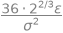

In [2]:
# 1. Declaración de símbolos con suposiciones físicas estrictas
distancia = sp.symbols("r", positive=True)
epsilon = sp.symbols("epsilon", positive=True)
sigma = sp.symbols("sigma", positive=True)

# 2. Construcción del potencial de Lennard-Jones
potencial = 4 * epsilon * ((sigma / distancia)**12 - (sigma / distancia)**6)

# 3. Fuerza como el gradiente negativo del potencial
fuerza = -sp.diff(potencial, distancia)

# 4. Distancia de equilibrio (donde la fuerza es 0)
# sp.solve devuelve una lista con las raíces, tomamos la única raíz [0]
distancia_equilibrio = sp.solve(fuerza, distancia)[0]

# 5. Energía en el mínimo del pozo (evaluamos V en r = r_eq)
energia_minima = sp.simplify(potencial.subs(distancia, distancia_equilibrio))

# 6. Constante elástica efectiva (segunda derivada de V evaluada en r_eq)
segunda_derivada = sp.diff(potencial, distancia, 2)
curvatura = sp.simplify(segunda_derivada.subs(distancia, distancia_equilibrio))

# (Opcional) Mostrar los resultados en pantalla para confirmar visualmente
display("Fuerza:", fuerza)
display("Distancia de equilibrio:", distancia_equilibrio)
display("Energía mínima:", energia_minima)
display("Curvatura en el mínimo:", curvatura)

## Ejercicio 2 (caso límite)

Un oscilador armónico de frecuencia propia $\omega$ es empujado por una
fuerza que oscila con **otra** frecuencia, $\Omega$:

$$m\,\ddot{x} = -m\omega^2 x + F_0 \cos(\Omega t),
\qquad x(0) = 0, \quad \dot{x}(0) = 0$$

La solución existe para cualquier par de frecuencias distintas. La pregunta
interesante es qué pasa cuando la fuerza se sintoniza con el oscilador,
$\Omega \to \omega$: ahí el denominador de la solución se anula, y hay que
tomar un **límite** para ver qué queda. Eso es la resonancia.

Completa la celda con estos nombres:

- `tiempo`, `masa`, `frecuencia_propia`, `frecuencia_forzamiento` y
  `fuerza_maxima`: los símbolos, con nombres `"t"`, `"m"`, `"omega"`,
  `"Omega"` y `"F_0"`. Los cinco son **positivos**.
- `posicion`: la función incógnita, `sp.Function("x")`.
- `ecuacion_forzada`: la ecuación de movimiento, escrita con `sp.Eq`.
- `solucion_forzada`: el resultado de `sp.dsolve` con las dos condiciones
  iniciales en `ics` (parte del reposo, desde el origen). Recuerda cómo se
  escribe la condición sobre la derivada: `posicion(tiempo).diff(tiempo).subs(tiempo, 0)`.
  Es una `Eq`, no una expresión.
- `movimiento`: solo la expresión de $x(t)$, es decir el `.rhs` de la
  solución.
- `movimiento_en_resonancia`: el límite de `movimiento` cuando
  `frecuencia_forzamiento` tiende a `frecuencia_propia`, con `sp.limit`.
  Ojo: el límite es **sobre la frecuencia**, no sobre el tiempo.

Cuando lo tengas, mira `movimiento_en_resonancia` y responde en una celda
de markdown, en dos o tres renglones: ¿por qué la amplitud crece sin
límite, y qué le falta a este modelo para describir un sistema real? La
respuesta corta a lo segundo cabe en una palabra, y es algo que el modelo
no incluye.

Un aviso: la forma exacta en que SymPy escriba la solución **no** tiene por
qué coincidir con la de tu compañero. Los tests comparan equivalencia
simbólica, no cadenas, así que cualquier forma correcta se da por buena.

'Fuerza:'

'Distancia de equilibrio:'

'Energía mínima:'

'Curvatura en el mínimo:'

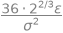

In [3]:
# 1. Declaración de símbolos con suposiciones físicas estrictas
distancia = sp.symbols("r", positive=True)
epsilon = sp.symbols("epsilon", positive=True)
sigma = sp.symbols("sigma", positive=True)

# 2. Construcción del potencial de Lennard-Jones
potencial = 4 * epsilon * ((sigma / distancia)**12 - (sigma / distancia)**6)

# 3. Fuerza como el gradiente negativo del potencial
fuerza = -sp.diff(potencial, distancia)

# 4. Distancia de equilibrio (donde la fuerza es 0)
# sp.solve devuelve una lista con las raíces, tomamos la única raíz [0]
distancia_equilibrio = sp.solve(fuerza, distancia)[0]

# 5. Energía en el mínimo del pozo (evaluamos V en r = r_eq)
energia_minima = sp.simplify(potencial.subs(distancia, distancia_equilibrio))

# 6. Constante elástica efectiva (segunda derivada de V evaluada en r_eq)
segunda_derivada = sp.diff(potencial, distancia, 2)
curvatura = sp.simplify(segunda_derivada.subs(distancia, distancia_equilibrio))

# (Opcional) Mostrar los resultados en pantalla para confirmar visualmente
display("Fuerza:", fuerza)
display("Distancia de equilibrio:", distancia_equilibrio)
display("Energía mínima:", energia_minima)
display("Curvatura en el mínimo:", curvatura)

_Escribe aquí tu respuesta a la pregunta del ejercicio 2._

## Resumen

Entrega esta tarea por **Pull Request dentro de tu fork**, como la de la
semana 4. El paso a paso está en
[`docs/git-guia.md`](../../docs/git-guia.md), y el checklist completo en
[`README.md`](README.md).

Antes de entregar, corre el notebook desde un kernel limpio
(`Kernel → Restart & Run All`) y confirma que llega hasta el final sin
errores. Al hacer push, GitHub Actions corre los tests y deja un check
✅ o ❌ en tu Pull Request.